In [317]:
# ============================================================
# FLIGHT DELAY ML MODEL
# AWS FLIGHT DELAY ANALYTICS PROJECT
#
# Environment:
# Amazon SageMaker AI - JupyterLab
#
# Data Source:
# Existing Gold layer in Amazon S3
#
# ML Problem:
# Predict whether an airline will experience a high-delay month.
#
# Prediction Unit:
# One airline × one month
#
# Target:
# HIGH_DELAY_MONTH
#     1 -> ARRIVAL_DELAY_RATE > 15%
#     0 -> ARRIVAL_DELAY_RATE <= 15%
#
# Model:
# Logistic Regression
#
# Training:
# 2019-2022
#
# Testing:
# 2023
# ============================================================


print("""
PROJECT OBJECTIVE

The existing AWS pipeline produces aggregated Gold datasets
for analytics.

For the ML component, we use the airline_summary Gold table.

The model predicts whether the CURRENT airline-month will be
a high-delay month using information available from the
PREVIOUS month.

This prevents temporal leakage.

The model is intentionally simple so that the complete
workflow can be understood and explained in an interview.
""")


PROJECT OBJECTIVE

The existing AWS pipeline produces aggregated Gold datasets
for analytics.

For the ML component, we use the airline_summary Gold table.

The model predicts whether the CURRENT airline-month will be
a high-delay month using information available from the
PREVIOUS month.

This prevents temporal leakage.

The model is intentionally simple so that the complete
workflow can be understood and explained in an interview.



In [318]:
# ============================================================
# 2. IMPORTS
# ============================================================

import boto3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [319]:
# ============================================================
# 3. CONFIGURATION
# ============================================================

AWS_REGION = "ap-southeast-2"

BUCKET_NAME = "elt-781504636344-ap-southeast-2-an"

GOLD_PATH = (
    f"s3://{BUCKET_NAME}/gold/airline_summary/"
)

GOLD_DATABASE = "flight_gold_db"
GOLD_TABLE = "airline_summary"

print("Gold data path:")
print(GOLD_PATH)

Gold data path:
s3://elt-781504636344-ap-southeast-2-an/gold/airline_summary/


In [320]:
# ============================================================
# 4. LOAD GOLD DATA
# ============================================================

GOLD_COLUMNS = [
    "AIRLINE",
    "TOTAL_FLIGHTS",
    "AVG_ARR_DELAY",
    "ARRIVAL_DELAY_RATE",
    "CANCELLATION_RATE",
    "Year",
    "Month"
]

print("Loading Gold airline_summary data...")

df = pd.read_parquet(
    GOLD_PATH,
    columns=GOLD_COLUMNS
)

print("Gold data loaded successfully.")

print(f"Rows    : {len(df):,}")
print(f"Columns : {len(df.columns)}")

display(df.head())

Loading Gold airline_summary data...
Gold data loaded successfully.
Rows    : 933
Columns : 7


,AIRLINE,TOTAL_FLIGHTS,AVG_ARR_DELAY,ARRIVAL_DELAY_RATE,CANCELLATION_RATE,Year,Month
0,Frontier Airlines Inc.,998,5.255102,0.392786,0.018036,2019,1
1,Republic Airline,2584,8.696884,0.362616,0.040635,2019,1
2,Allegiant Air,692,8.637830,0.430636,0.010116,2019,1
3,PSA Airlines Inc.,2346,1.993841,0.334612,0.028986,2019,1
4,Envoy Air,2664,7.574980,0.380631,0.076201,2019,1


In [321]:
# ============================================================
# 5. INITIAL DATA INSPECTION
# ============================================================

print("Shape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Shape:
(933, 7)

Columns:
['AIRLINE', 'TOTAL_FLIGHTS', 'AVG_ARR_DELAY', 'ARRIVAL_DELAY_RATE', 'CANCELLATION_RATE', 'Year', 'Month']

Data types:
AIRLINE                 object
TOTAL_FLIGHTS            int64
AVG_ARR_DELAY          float64
ARRIVAL_DELAY_RATE     float64
CANCELLATION_RATE      float64
Year                  category
Month                 category
dtype: object

Missing values:
AIRLINE               0
TOTAL_FLIGHTS         0
AVG_ARR_DELAY         0
ARRIVAL_DELAY_RATE    0
CANCELLATION_RATE     0
Year                  0
Month                 0
dtype: int64

Duplicate rows:
0


In [322]:
# ============================================================
# 6. DATA CLEANING
# ============================================================

# Convert columns to appropriate types

df["Year"] = pd.to_numeric(
    df["Year"],
    errors="coerce"
)

df["Month"] = pd.to_numeric(
    df["Month"],
    errors="coerce"
)

numeric_columns = [
    "TOTAL_FLIGHTS",
    "AVG_ARR_DELAY",
    "ARRIVAL_DELAY_RATE",
    "CANCELLATION_RATE"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

# Remove rows without essential identifiers
df = df.dropna(
    subset=[
        "AIRLINE",
        "Year",
        "Month"
    ]
)

# Convert year/month to integers
df["Year"] = df["Year"].astype(int)
df["Month"] = df["Month"].astype(int)

# Sort chronologically
df = df.sort_values(
    ["AIRLINE", "Year", "Month"]
).reset_index(drop=True)

print(f"Rows after cleaning: {len(df):,}")

display(df.head())

Rows after cleaning: 933


,AIRLINE,TOTAL_FLIGHTS,AVG_ARR_DELAY,ARRIVAL_DELAY_RATE,CANCELLATION_RATE,Year,Month
0,Alaska Airlines Inc.,2078,0.559705,0.347449,0.016362,2019,1
1,Alaska Airlines Inc.,1957,11.751750,0.457844,0.045989,2019,2
2,Alaska Airlines Inc.,2220,0.342261,0.368018,0.006306,2019,3
3,Alaska Airlines Inc.,2123,-2.013790,0.306171,0.008008,2019,4
4,Alaska Airlines Inc.,2335,0.334916,0.357173,0.005996,2019,5


In [323]:
# ============================================================
# 7. VALIDATE GOLD GRAIN
# ============================================================

duplicate_grain = df.duplicated(
    subset=[
        "AIRLINE",
        "Year",
        "Month"
    ]
).sum()

print(
    "Duplicate AIRLINE × Year × Month rows:",
    duplicate_grain
)

if duplicate_grain == 0:
    print("Gold grain is valid.")
else:
    print("WARNING: Duplicate Gold grain detected.")

Duplicate AIRLINE × Year × Month rows: 0
Gold grain is valid.


Target distribution:
HIGH_DELAY_MONTH
1    620
0    313
Name: count, dtype: int64

Target distribution (%):
HIGH_DELAY_MONTH
1    66.45
0    33.55
Name: proportion, dtype: float64


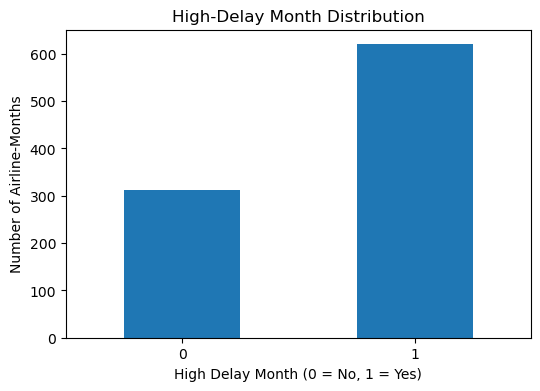

In [324]:
# ============================================================
# 8. CREATE TARGET
# ============================================================

HIGH_DELAY_THRESHOLD = 0.28

df["HIGH_DELAY_MONTH"] = (
    df["ARRIVAL_DELAY_RATE"] > HIGH_DELAY_THRESHOLD
).astype(int)

print("Target distribution:")
print(
    df["HIGH_DELAY_MONTH"].value_counts()
)

print("\nTarget distribution (%):")
print(
    df["HIGH_DELAY_MONTH"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# Target distribution visualization

df["HIGH_DELAY_MONTH"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("High-Delay Month Distribution")
plt.xlabel("High Delay Month (0 = No, 1 = Yes)")
plt.ylabel("Number of Airline-Months")
plt.xticks(rotation=0)

plt.show()

In [325]:
# ============================================================
# 9. CREATE PREVIOUS-MONTH FEATURES
# ============================================================

# Previous month's arrival delay rate
df["PREV_ARRIVAL_DELAY_RATE"] = (
    df.groupby("AIRLINE")["ARRIVAL_DELAY_RATE"]
      .shift(1)
)

# Previous month's average arrival delay
df["PREV_AVG_ARR_DELAY"] = (
    df.groupby("AIRLINE")["AVG_ARR_DELAY"]
      .shift(1)
)

# Previous month's flight volume
df["PREV_TOTAL_FLIGHTS"] = (
    df.groupby("AIRLINE")["TOTAL_FLIGHTS"]
      .shift(1)
)

# Previous month's cancellation rate
df["PREV_CANCELLATION_RATE"] = (
    df.groupby("AIRLINE")["CANCELLATION_RATE"]
      .shift(1)
)

display(
    df[
        [
            "AIRLINE",
            "Year",
            "Month",
            "PREV_ARRIVAL_DELAY_RATE",
            "PREV_AVG_ARR_DELAY",
            "PREV_TOTAL_FLIGHTS",
            "PREV_CANCELLATION_RATE",
            "HIGH_DELAY_MONTH"
        ]
    ].head(15)
)

,AIRLINE,Year,Month,PREV_ARRIVAL_DELAY_RATE,PREV_AVG_ARR_DELAY,PREV_TOTAL_FLIGHTS,PREV_CANCELLATION_RATE,HIGH_DELAY_MONTH
0,Alaska Airlines Inc.,2019,1,NaN,NaN,NaN,NaN,1
1,Alaska Airlines Inc.,2019,2,0.347449,0.559705,2078.0,0.016362,1
2,Alaska Airlines Inc.,2019,3,0.457844,11.751750,1957.0,0.045989,1
3,Alaska Airlines Inc.,2019,4,0.368018,0.342261,2220.0,0.006306,1
4,Alaska Airlines Inc.,2019,5,0.306171,-2.013790,2123.0,0.008008,1
5,Alaska Airlines Inc.,2019,6,0.357173,0.334916,2335.0,0.005996,1
6,Alaska Airlines Inc.,2019,7,0.355725,1.367816,2367.0,0.007182,1
7,Alaska Airlines Inc.,2019,8,0.313609,-1.009964,2535.0,0.007495,1
8,Alaska Airlines Inc.,2019,9,0.389384,3.325108,2581.0,0.009299,1
9,Alaska Airlines Inc.,2019,10,0.369575,0.220898,2189.0,0.003198,1


In [326]:
# ============================================================
# 10. CALENDAR FEATURES
# ============================================================

# Month itself can capture seasonal patterns.
#
# We already have Month, but converting it to a categorical
# variable allows Logistic Regression to learn separate
# patterns for different months.

df["MONTH_CATEGORY"] = df["Month"].astype(str)

print(
    df[
        [
            "AIRLINE",
            "Year",
            "Month",
            "MONTH_CATEGORY"
        ]
    ].head()
)

                AIRLINE  Year  Month MONTH_CATEGORY
0  Alaska Airlines Inc.  2019      1              1
1  Alaska Airlines Inc.  2019      2              2
2  Alaska Airlines Inc.  2019      3              3
3  Alaska Airlines Inc.  2019      4              4
4  Alaska Airlines Inc.  2019      5              5


In [327]:
# ============================================================
# 11. REMOVE ROWS WITHOUT PREVIOUS-MONTH INFORMATION
# ============================================================

required_history = [
    "PREV_ARRIVAL_DELAY_RATE",
    "PREV_AVG_ARR_DELAY",
    "PREV_TOTAL_FLIGHTS",
    "PREV_CANCELLATION_RATE"
]

df_ml = df.dropna(
    subset=required_history
).copy()

print(
    f"Rows available for ML: {len(df_ml):,}"
)

Rows available for ML: 915


In [328]:
# ============================================================
# 12. DEFINE FEATURES AND TARGET
# ============================================================

FEATURES = [
    "AIRLINE",
    "MONTH_CATEGORY",
    "PREV_ARRIVAL_DELAY_RATE",
    "PREV_AVG_ARR_DELAY",
    "PREV_TOTAL_FLIGHTS",
    "PREV_CANCELLATION_RATE"
]

TARGET = "HIGH_DELAY_MONTH"

X = df_ml[FEATURES]
y = df_ml[TARGET]

print("Features:")
for feature in FEATURES:
    print("-", feature)

print("\nTarget:")
print(TARGET)

# =========================================================================================

# AIRLINE
# → Different airlines can have different operational patterns.

# MONTH_CATEGORY
# → Captures seasonal effects.

# PREV_ARRIVAL_DELAY_RATE
# → Previous month's delay performance may indicate continuing
#   operational conditions.

# PREV_AVG_ARR_DELAY
# → Previous month's average delay provides another indicator
#   of recent delay severity.

# PREV_TOTAL_FLIGHTS
# → Previous month's traffic volume gives an indication of
#   the airline's operational load.

# PREV_CANCELLATION_RATE
# → Recent cancellation activity can indicate operational
#   disruption.

# =========================================================================================

# CURRENT ARRIVAL_DELAY_RATE
# CURRENT AVG_ARR_DELAY
# CURRENT DELAYED_ARRIVALS

# are not features.

# They are information from the month we're trying to predict.

Features:
- AIRLINE
- MONTH_CATEGORY
- PREV_ARRIVAL_DELAY_RATE
- PREV_AVG_ARR_DELAY
- PREV_TOTAL_FLIGHTS
- PREV_CANCELLATION_RATE

Target:
HIGH_DELAY_MONTH


In [329]:
# ============================================================
# 14. CHRONOLOGICAL TRAIN / TEST SPLIT
# ============================================================

train_df = df_ml[
    df_ml["Year"] <= 2022
].copy()

test_df = df_ml[
    df_ml["Year"] == 2023
].copy()

X_train = train_df[FEATURES]
y_train = train_df[TARGET]

X_test = test_df[FEATURES]
y_test = test_df[TARGET]

print("TRAINING DATA")
print("-" * 40)

print(f"Rows: {len(X_train):,}")

print(
    f"Years: "
    f"{train_df['Year'].min()} - "
    f"{train_df['Year'].max()}"
)

print("\nTEST DATA")
print("-" * 40)

print(f"Rows: {len(X_test):,}")

print(
    f"Years: "
    f"{test_df['Year'].min()} - "
    f"{test_df['Year'].max()}"
)

TRAINING DATA
----------------------------------------
Rows: 795
Years: 2019 - 2022

TEST DATA
----------------------------------------
Rows: 120
Years: 2023 - 2023


In [330]:
# ============================================================
# 15. CLASS BALANCE
# ============================================================

print("Training target distribution:")
print(
    y_train.value_counts()
)

print("\nTraining target percentage:")
print(
    y_train
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nTesting target distribution:")
print(
    y_test.value_counts()
)

Training target distribution:
HIGH_DELAY_MONTH
1    496
0    299
Name: count, dtype: int64

Training target percentage:
HIGH_DELAY_MONTH
1    62.39
0    37.61
Name: proportion, dtype: float64

Testing target distribution:
HIGH_DELAY_MONTH
1    108
0     12
Name: count, dtype: int64


In [331]:
# ============================================================
# 16. PREPROCESSING FOR XGBOOST
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer


# ------------------------------------------------------------
# Categorical features
# ------------------------------------------------------------

categorical_features = [
    "AIRLINE",
    "MONTH_CATEGORY"
]


# ------------------------------------------------------------
# Numerical features
# ------------------------------------------------------------

numerical_features = [
    "PREV_ARRIVAL_DELAY_RATE",
    "PREV_AVG_ARR_DELAY",
    "PREV_TOTAL_FLIGHTS",
    "PREV_CANCELLATION_RATE"
]


# ------------------------------------------------------------
# Numerical preprocessing
#
# XGBoost does not require StandardScaler.
# We only handle missing values.
# ------------------------------------------------------------

numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)


# ------------------------------------------------------------
# Categorical preprocessing
# ------------------------------------------------------------

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)


# ------------------------------------------------------------
# Combine preprocessing
# ------------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numerical_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ]
)


print("XGBoost preprocessing pipeline created.")

XGBoost preprocessing pipeline created.


In [332]:
# ============================================================
# 17. IMPORT XGBOOST
# ============================================================

try:
    from xgboost import XGBClassifier

    print("XGBoost is already installed.")

except ImportError:
    print("XGBoost not found. Installing...")

    %pip install -q xgboost

    from xgboost import XGBClassifier

    print("XGBoost installed successfully.")

XGBoost is already installed.


In [333]:
# ============================================================
# 18. CLASS IMBALANCE
# ============================================================

negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

print("Training class distribution")
print("-" * 40)

print(f"Normal-delay months : {negative_count:,}")
print(f"High-delay months   : {positive_count:,}")

if positive_count > 0:
    scale_pos_weight = negative_count / positive_count
else:
    scale_pos_weight = 1.0

print(
    f"\nscale_pos_weight: {scale_pos_weight:.3f}"
)

Training class distribution
----------------------------------------
Normal-delay months : 299
High-delay months   : 496

scale_pos_weight: 0.603


In [334]:
# ============================================================
# 19. XGBOOST CLASSIFIER
# ============================================================

# n_estimators = 300
# → Maximum number of boosting trees

# max_depth = 4
# → Keeps individual trees relatively shallow

# learning_rate = 0.05
# → Gradual learning

# subsample = 0.8
# → Uses 80% of training rows per boosting iteration

# colsample_bytree = 0.8
# → Uses 80% of features per tree

# random_state = 42
# → Reproducible results

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,

    subsample=0.8,
    colsample_bytree=0.8,

    min_child_weight=1,
    reg_lambda=1.0,

    objective="binary:logistic",

    eval_metric="logloss",

    scale_pos_weight=scale_pos_weight,

    random_state=42,
    n_jobs=-1
)


print("XGBoost classifier created successfully.")

XGBoost classifier created successfully.


In [335]:
# ============================================================
# 20. COMPLETE XGBOOST PIPELINE
# ============================================================

model_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            xgb_model
        )
    ]
)


print("Complete XGBoost pipeline created.")

Complete XGBoost pipeline created.


In [336]:
# ============================================================
# 21. MODEL TRAINING
# ============================================================

print("Training XGBoost model...")
print()

model_pipeline.fit(
    X_train,
    y_train
)

print()
print("XGBoost training completed successfully.")

Training XGBoost model...


XGBoost training completed successfully.


In [337]:
# ============================================================
# 22. GENERATE PREDICTIONS
# ============================================================

y_pred = model_pipeline.predict(
    X_test
)

y_probability = (
    model_pipeline
    .predict_proba(X_test)[:, 1]
)


print("Predictions generated successfully.")

print("\nFirst 10 predictions:")
print(y_pred[:10])

print("\nFirst 10 prediction probabilities:")
print(
    np.round(
        y_probability[:10],
        3
    )
)

Predictions generated successfully.

First 10 predictions:
[1 1 1 1 1 1 1 1 1 1]

First 10 prediction probabilities:
[0.975 0.996 0.971 0.993 0.998 0.992 0.994 0.988 0.938 0.958]


In [338]:
# ============================================================
# 23. MODEL EVALUATION
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_probability
)


print("=" * 60)
print("XGBOOST MODEL PERFORMANCE")
print("=" * 60)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

XGBOOST MODEL PERFORMANCE
Accuracy : 0.8333
Precision: 0.9151
Recall   : 0.8981
F1 Score : 0.9065
ROC-AUC  : 0.8426
